# 1. Diagnóstico sobre Bronze
Primera mirada a los datos sin retocar: dimensiones, tipos, muestra y faltantes.

In [1]:
# 1) Importamos las librerías con sus alias convencionales
import pandas as pd                 # tablas (DataFrame)
import numpy as np                  # cálculo numérico y condiciones vectorizadas
import matplotlib.pyplot as plt     # gráficos base (Seaborn se apoya en él)
import seaborn as sns               # gráficos estadísticos de alto nivel
from scipy import stats             # pruebas estadísticas (Parte 6)

from flows.common.paths import BRONZE, SILVER, GOLD, BRONZE_LABELED_NAME, SILVER_NAME

# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.titlesize'] = 13

# 3) Cargamos Bronze (nunca la URL: la ingesta ya la guardó)
df = pd.read_csv(BRONZE / BRONZE_LABELED_NAME)

## Paso 1. Dimensiones
¿Cuántos pasajeros (filas) y variables (columnas) hay?

In [2]:
# shape es un ATRIBUTO: devuelve (filas, columnas)
df.shape

(891, 12)

## Paso 2. Variables y tipos
Comparamos los no nulos de cada columna con el total de filas (891) para detectar faltantes.

In [3]:
# info() es un MÉTODO: imprime nombre, no nulos y tipo de cada columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    float64
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(3), int64(4), str(5)
memory usage: 118.9 KB


## Paso 3. Primeras 10 filas

In [4]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0.0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0.0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0.0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1.0,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1.0,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


## Paso 4. Estadísticas descriptivas

In [5]:
# Columnas numéricas: conteo, media, desviación, mínimo, cuartiles, máximo
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
# Columnas NO numéricas: conteo, valores únicos, más frecuente (top) y su frecuencia
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


## Paso 5. Datos faltantes

In [7]:
# Conteo de nulos por columna (True cuenta como 1)
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

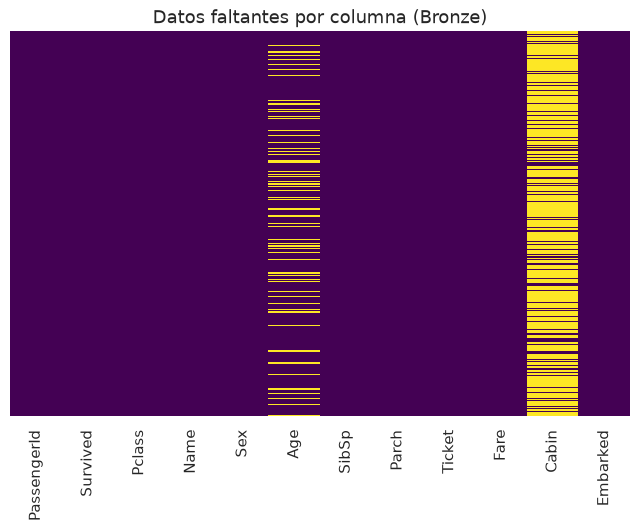

In [8]:
# Mapa de calor: cada línea amarilla es un dato faltante
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Datos faltantes por columna (Bronze)')
plt.show()

# 2. Conociendo a los pasajeros (Silver)
A partir de aquí el cuaderno lee la capa Silver.

In [9]:
# Recargamos desde Silver (incluye la columna Person creada en el módulo)
df = pd.read_parquet(SILVER / SILVER_NAME)
df.shape

(891, 13)

## Paso 6. Distribución por género y su cruce con la clase

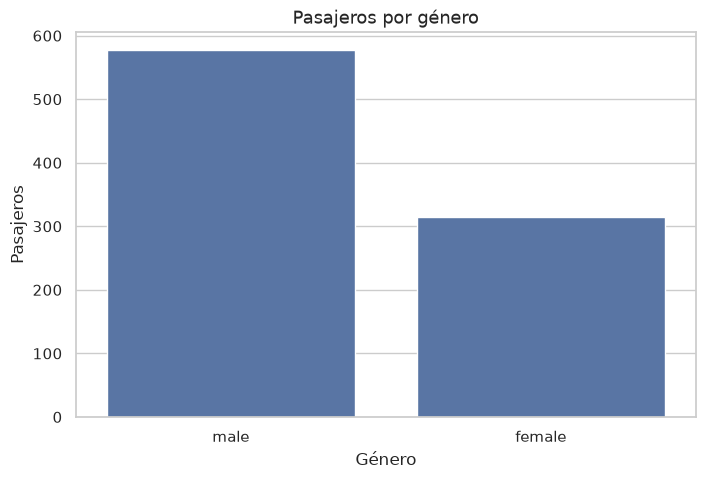

In [10]:
sns.countplot(data=df, x='Sex')
plt.title('Pasajeros por género'); plt.xlabel('Género'); plt.ylabel('Pasajeros')
plt.show()

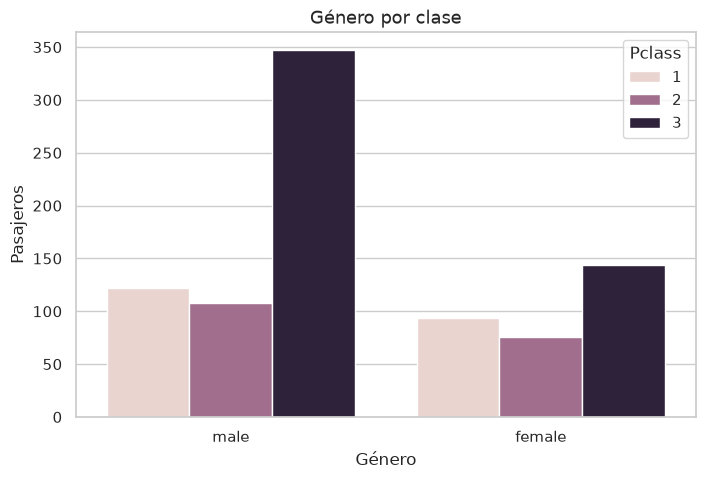

In [11]:
sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Género por clase'); plt.xlabel('Género'); plt.ylabel('Pasajeros')
plt.show()

In [12]:
# Proporción de cada género DENTRO de cada clase (cada columna suma 1)
pd.crosstab(df['Sex'], df['Pclass'], normalize='columns').round(3)

Pclass,1,2,3
Sex,,,
female,0.435,0.413,0.293
male,0.565,0.587,0.707


## Paso 7. Distribución de edades
Age todavía no está imputada en Silver: solo vemos pasajeros con edad conocida.

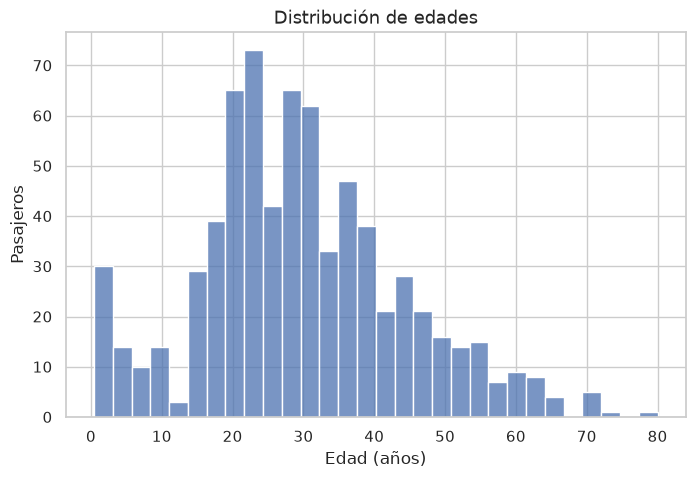

In [14]:
sns.histplot(df['Age'].dropna(), bins=30)
plt.title('Distribución de edades'); plt.xlabel('Edad (años)'); plt.ylabel('Pasajeros')
plt.show()

In [15]:
# Edad promedio (Pandas ignora los NaN)
df['Age'].mean()

np.float64(29.69911764705882)

In [16]:
# Mediana, mínimo y máximo
df['Age'].median(), df['Age'].min(), df['Age'].max()

(np.float64(28.0), np.float64(0.42), np.float64(80.0))

## Paso 8. Variable Person (hombre, mujer o niño)
Creada en `flows/01_data_engineering.py` → `add_person`. Un pasajero sin edad nunca es `child`: conserva su sexo.

In [17]:
df['Person'].value_counts()

Person
male      537
female    271
child      83
Name: count, dtype: int64

### Reto 8.1. ¿Cuántos niños "faltan" por edad desconocida?

In [18]:
n_sin_edad = df['Age'].isnull().sum()

# Proporción de niños entre quienes SÍ tienen edad
con_edad = df[df['Age'].notna()]
prop_ninos = (con_edad['Person'] == 'child').mean()

ninos_faltantes = n_sin_edad * prop_ninos
print(f'Pasajeros sin edad: {n_sin_edad}')
print(f'Proporción de niños entre los que tienen edad: {prop_ninos:.3f}')
print(f'Niños que probablemente "faltan": {ninos_faltantes:.0f}')

Pasajeros sin edad: 177
Proporción de niños entre los que tienen edad: 0.116
Niños que probablemente "faltan": 21


## Paso 9. ¿Cuántos niños viajaban en cada clase?

In [19]:
pd.crosstab(df['Pclass'], df['Person'])

Person,child,female,male
Pclass,,,
1,6,91,119
2,19,66,99
3,58,114,319


## Paso 10. Densidad (KDE) de la edad
`common_norm=False` normaliza cada grupo por separado para que los grupos grandes no aplasten a los pequeños.

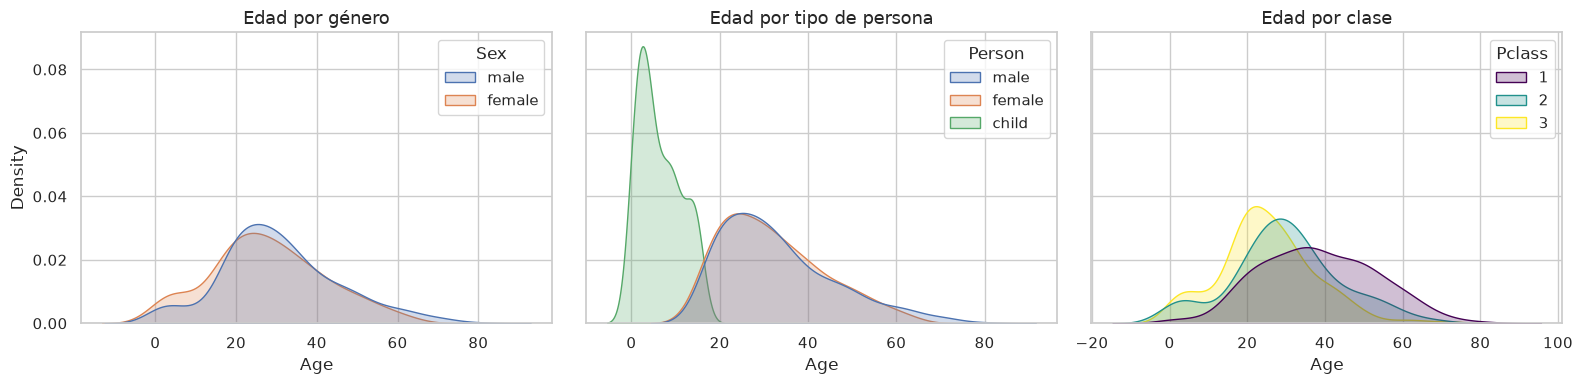

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
sns.kdeplot(data=df, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
sns.kdeplot(data=df, x='Age', hue='Pclass', fill=True, common_norm=False,
            palette='viridis', ax=axes[2])
axes[0].set_title('Edad por género')
axes[1].set_title('Edad por tipo de persona')
axes[2].set_title('Edad por clase')
plt.tight_layout(); plt.show()

# 3. Ubicación, embarque y composición familiar

In [13]:
# Recargamos Silver para tener las columnas nuevas (TCabin, HasCabin, Familia, Alone, Survivor)
df = pd.read_parquet(SILVER / SILVER_NAME)
df.shape

(891, 18)

## Paso 11. Cubierta de la cabina
`TCabin` es la primera letra de `Cabin`; `X` = cabina desconocida.

In [14]:
df['TCabin'].value_counts()

TCabin
X    687
C     59
B     47
D     33
E     32
A     15
F     13
G      4
T      1
Name: count, dtype: int64

## Paso 12. Pasajeros por cubierta (con depuración de anómalos)

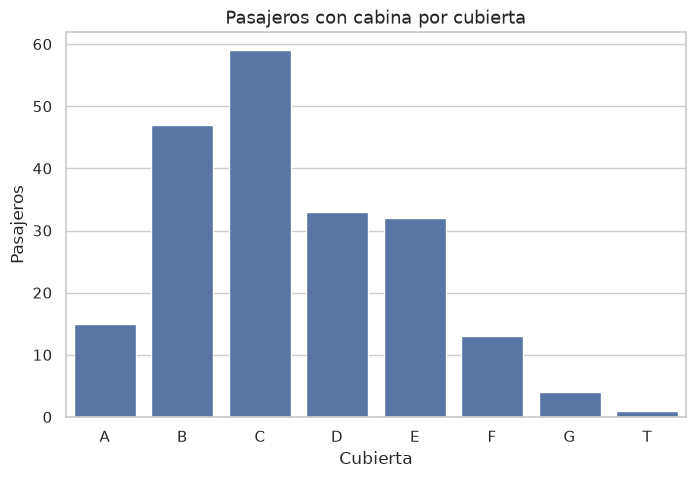

In [15]:
# Solo cabinas conocidas
cubierta = df.loc[df['TCabin'] != 'X', 'TCabin']

sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Pasajeros con cabina por cubierta'); plt.xlabel('Cubierta'); plt.ylabel('Pasajeros')
plt.show()

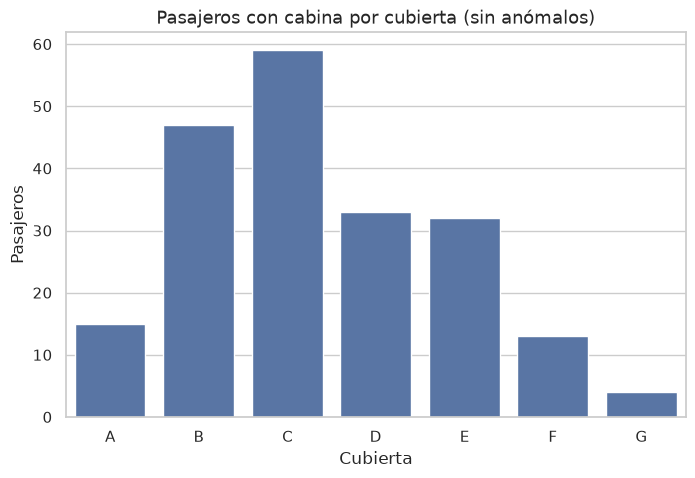

In [16]:
# La cubierta 'T' tiene un solo registro: se excluye SOLO del gráfico, no de df
cubierta = cubierta[cubierta != 'T']

sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Pasajeros con cabina por cubierta (sin anómalos)'); plt.xlabel('Cubierta'); plt.ylabel('Pasajeros')
plt.show()

## Paso 13. Puerto de embarque y clase

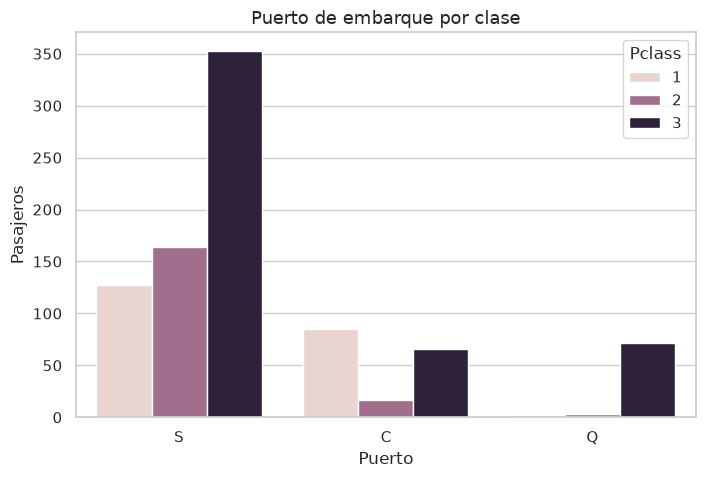

In [17]:
sns.countplot(data=df, x='Embarked', hue='Pclass', order=['S', 'C', 'Q'])
plt.title('Puerto de embarque por clase'); plt.xlabel('Puerto'); plt.ylabel('Pasajeros')
plt.show()

In [18]:
# Composición de clases de cada puerto (cada fila suma 1)
pd.crosstab(df['Embarked'], df['Pclass'], normalize='index').round(3)

Pclass,1,2,3
Embarked,,,
C,0.506,0.101,0.393
Q,0.026,0.039,0.935
S,0.197,0.255,0.548


## Paso 14. Variable Alone (solo vs. con familia)
Creada en el módulo → `add_family_features`: `Familia = SibSp + Parch`.

In [19]:
df['Alone'].value_counts(normalize=True)

Alone
Alone          0.602694
with Family    0.397306
Name: proportion, dtype: float64

## Paso 15. Distribución de Alone

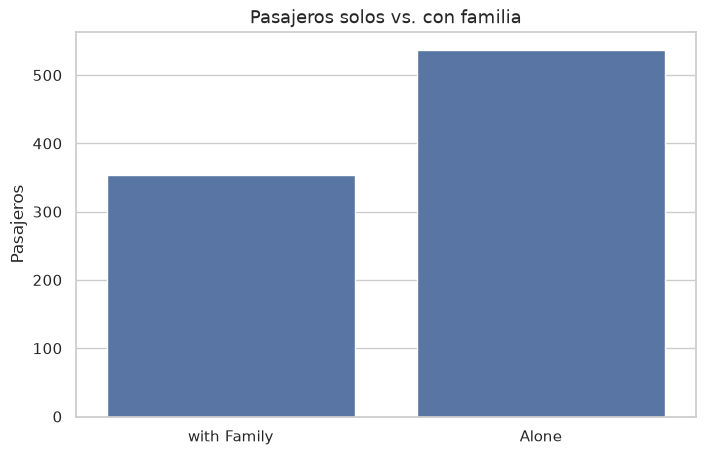

In [20]:
sns.countplot(data=df, x='Alone')
plt.title('Pasajeros solos vs. con familia'); plt.xlabel(''); plt.ylabel('Pasajeros')
plt.show()

# 4. Análisis de supervivencia
La media de `Survived` (0/1) es la tasa de supervivencia. Las barras verticales de los gráficos de puntos son intervalos de confianza al 95 %.

## Paso 16. Panorama general

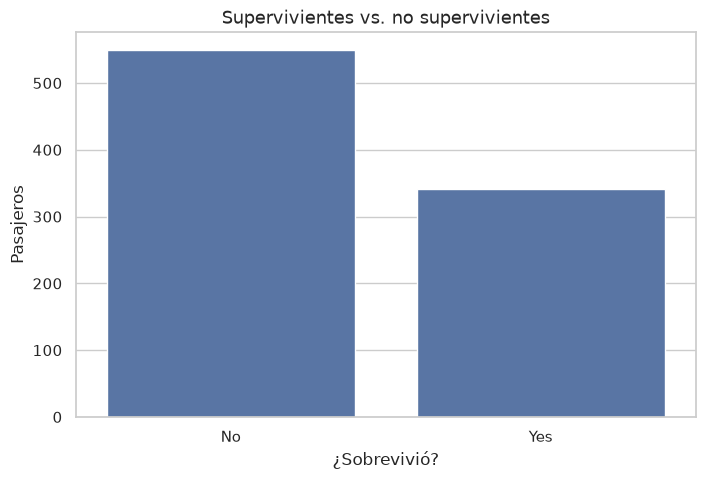

In [21]:
sns.countplot(data=df, x='Survivor', order=['No', 'Yes'])
plt.title('Supervivientes vs. no supervivientes'); plt.xlabel('¿Sobrevivió?'); plt.ylabel('Pasajeros')
plt.show()

In [22]:
# Tasa general de supervivencia (debería rondar 0.38)
df['Survived'].mean()

np.float64(0.3838383838383838)

## Paso 17. Supervivencia por clase

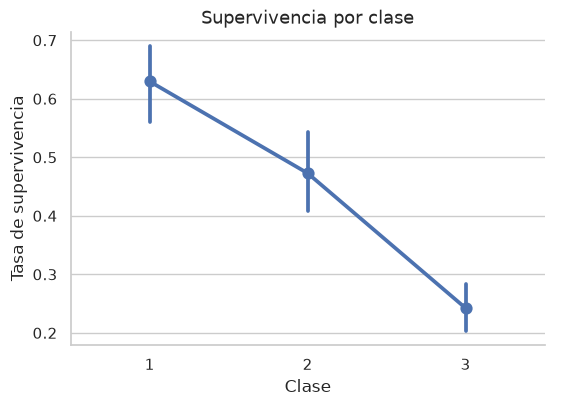

In [23]:
g = sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
g.set_axis_labels('Clase', 'Tasa de supervivencia')
plt.title('Supervivencia por clase')
plt.show()

## Paso 18. Supervivencia por clase y tipo de persona

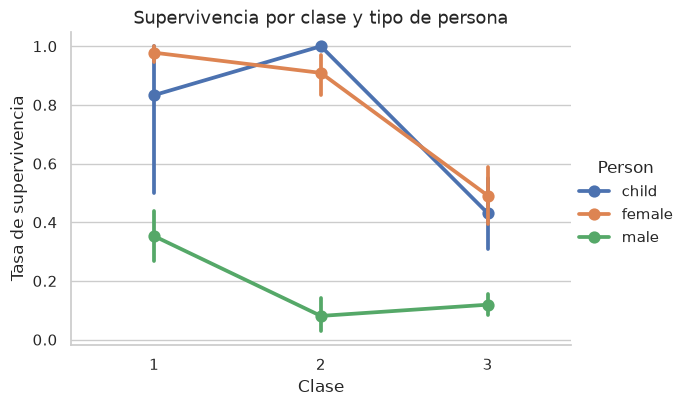

In [24]:
g = sns.catplot(data=df, x='Pclass', y='Survived', hue='Person', kind='point',
                hue_order=['child', 'female', 'male'], height=4, aspect=1.5)
g.set_axis_labels('Clase', 'Tasa de supervivencia')
plt.title('Supervivencia por clase y tipo de persona')
plt.show()

## Paso 19. Edad y supervivencia
Con `y` binaria, la recta es solo una aproximación visual; `x_bins` muestra la tasa media por grupo de edad.

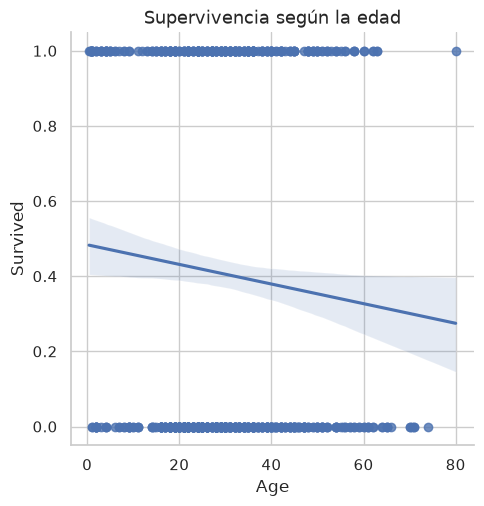

In [25]:
sns.lmplot(data=df, x='Age', y='Survived')
plt.title('Supervivencia según la edad')
plt.show()

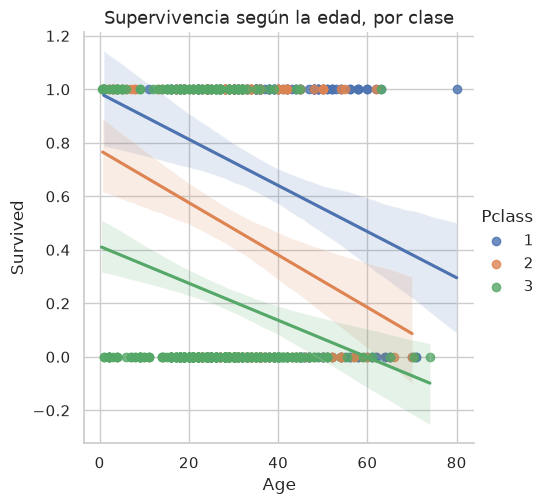

In [26]:
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass')
plt.title('Supervivencia según la edad, por clase')
plt.show()

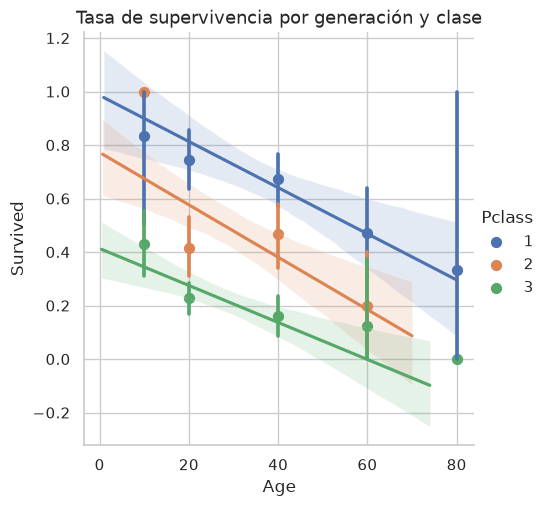

In [27]:
generaciones = [10, 20, 40, 60, 80]
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', x_bins=generaciones)
plt.title('Tasa de supervivencia por generación y clase')
plt.show()

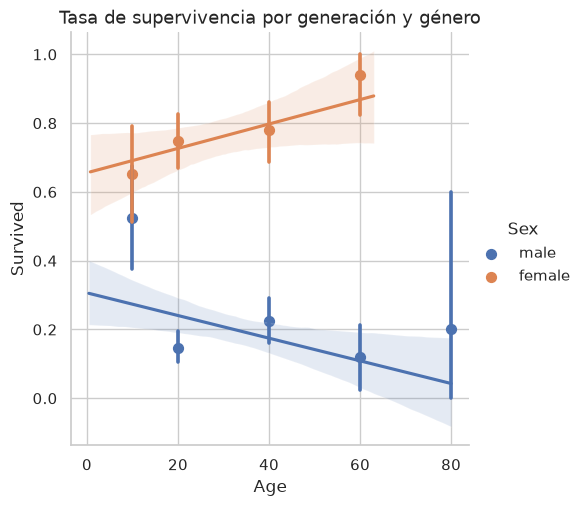

In [28]:
sns.lmplot(data=df, x='Age', y='Survived', hue='Sex', x_bins=generaciones)
plt.title('Tasa de supervivencia por generación y género')
plt.show()

## Paso 20. Relación tarifa-edad

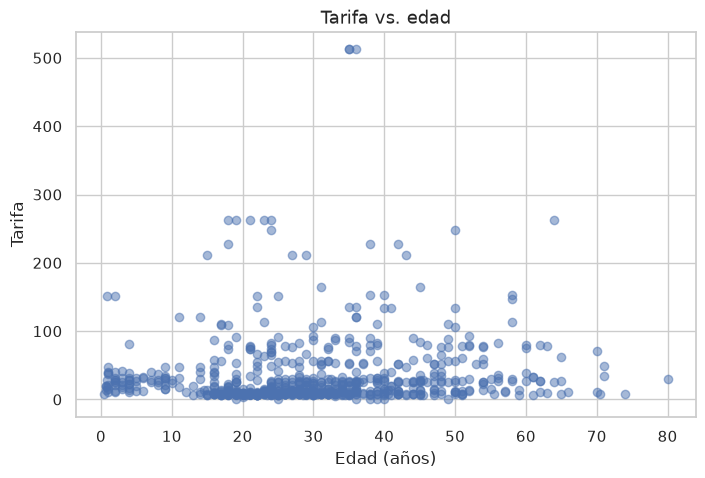

In [29]:
plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.title('Tarifa vs. edad'); plt.xlabel('Edad (años)'); plt.ylabel('Tarifa')
plt.show()

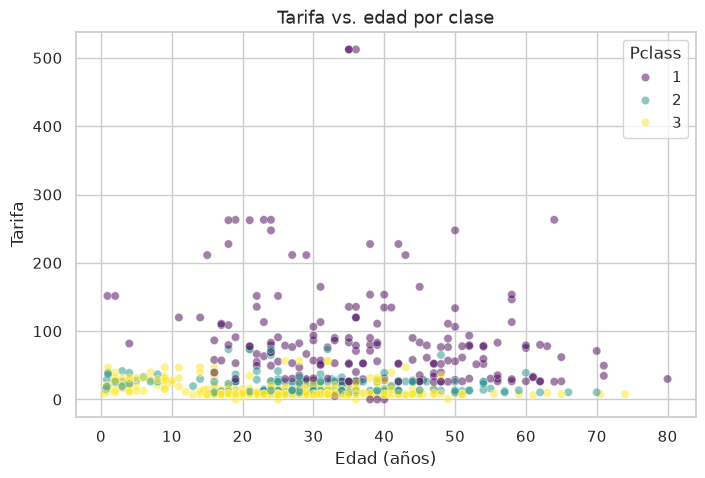

In [30]:
sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
plt.title('Tarifa vs. edad por clase'); plt.xlabel('Edad (años)'); plt.ylabel('Tarifa')
plt.show()

# 5. Limpieza y preparación de datos
Un dato faltante puede (a) eliminarse, (b) imputarse o (c) conservarse como categoría propia. **Ninguna opción es neutral.**
La limpieza se hizo en `flows/01_data_engineering.py`; aquí verificamos su efecto comparando Bronze (original) con Silver (limpio).

In [32]:
# Imports adicionales para las Partes 5 a 9
import importlib
from flows.common.paths import SILVER_FINAL_NAME

agg = importlib.import_module('flows.03_aggregation')   # se usa desde la Parte 6

bronze = pd.read_csv(BRONZE / BRONZE_LABELED_NAME)   # datos originales
df = pd.read_parquet(SILVER / SILVER_NAME)           # datos limpios
df.shape

(891, 25)

## Paso 21. Datos faltantes en `Embarked`
`impute_embarked` rellena con la moda y `encode_categoricals` crea `NEmbarked` (S → 0, C → 1, Q → 2).

In [33]:
print('Faltantes en Embarked (Bronze):', bronze['Embarked'].isnull().sum())
print('Moda de Embarked:', bronze['Embarked'].mode()[0])
print('Faltantes en Embarked (Silver):', df['Embarked'].isnull().sum())

Faltantes en Embarked (Bronze): 2
Moda de Embarked: S
Faltantes en Embarked (Silver): 0


In [34]:
# Verificación de la codificación
pd.crosstab(df['Embarked'], df['NEmbarked'])

NEmbarked,0,1,2
Embarked,,,
C,0,168,0
Q,0,0,77
S,646,0,0


In [35]:
print('Edades faltantes (AgeOriginal):', df['AgeOriginal'].isnull().sum())
print('Edades faltantes (Age imputada):', df['Age'].isnull().sum())
print('Filas imputadas:', df['AgeImputada'].sum())

Edades faltantes (AgeOriginal): 177
Edades faltantes (Age imputada): 0
Filas imputadas: 177


In [36]:
# Promedio de edad por género: el valor con el que se rellenó cada grupo
df.groupby('Sex')['AgeOriginal'].mean()

Sex
female    27.915709
male      30.726645
Name: AgeOriginal, dtype: float64

### Reto 22.1. ¿Qué le pasa a la edad al imputar?

Desviación estándar ANTES de imputar:   14.53
Desviación estándar DESPUÉS de imputar: 13.01


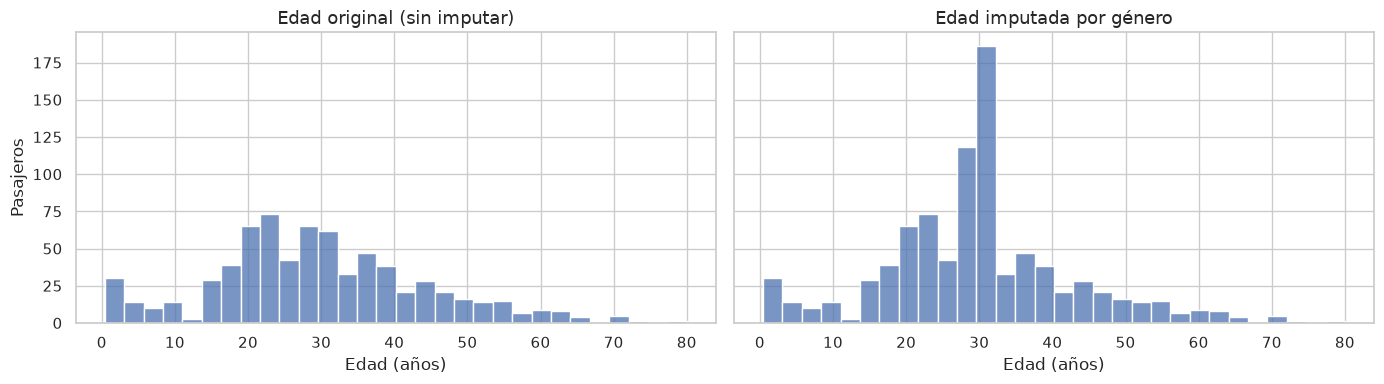

In [37]:
print(f"Desviación estándar ANTES de imputar:   {df['AgeOriginal'].std():.2f}")
print(f"Desviación estándar DESPUÉS de imputar: {df['Age'].std():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
sns.histplot(df['AgeOriginal'].dropna(), bins=30, ax=axes[0])
axes[0].set_title('Edad original (sin imputar)')
sns.histplot(df['Age'], bins=30, ax=axes[1])
axes[1].set_title('Edad imputada por género')
for ax in axes:
    ax.set_xlabel('Edad (años)'); ax.set_ylabel('Pasajeros')
plt.tight_layout(); plt.show()

## Paso 23. `Sex` a número
`NSex`: female → 0, male → 1.

In [38]:
pd.crosstab(df['Sex'], df['NSex'])

NSex,0,1
Sex,,
female,314,0
male,0,577


## Paso 24. Tratamiento de `Cabin`
`NCabin` usa un mapa **fijo** sobre `DECKS` (A=0 … X=8), así los números no cambian si una cubierta desaparece de los datos.

In [39]:
pd.crosstab(df['TCabin'], df['NCabin'])

NCabin,0,1,2,3,4,5,6,7,8
TCabin,,,,,,,,,
A,15,0,0,0,0,0,0,0,0
B,0,47,0,0,0,0,0,0,0
C,0,0,59,0,0,0,0,0,0
D,0,0,0,33,0,0,0,0,0
E,0,0,0,0,32,0,0,0,0
F,0,0,0,0,0,13,0,0,0
G,0,0,0,0,0,0,4,0,0
T,0,0,0,0,0,0,0,1,0
X,0,0,0,0,0,0,0,0,687


## Paso 25. Títulos extraídos del nombre

In [40]:
titulos_originales = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()
titulos_originales.value_counts()

Name
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [41]:
pd.crosstab(titulos_originales, df['Sex'])

Sex,female,male
Name,,
Capt,0,1
Col,0,2
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40
Miss,182,0


## Paso 26. Títulos consolidados

In [42]:
df['TTitulo'].value_counts()

TTitulo
Mr      557
Miss    186
Mrs     127
Otro     21
Name: count, dtype: int64

In [43]:
pd.crosstab(df['TTitulo'], df['NTitulo'])

NTitulo,0,1,2,3
TTitulo,,,,
Miss,0,0,186,0
Mr,557,0,0,0
Mrs,0,127,0,0
Otro,0,0,0,21


# 6. Correlaciones y estadísticas por grupos
La correlación de Pearson mide relación **lineal** (−1 a +1), no implica causalidad y es poco informativa para categóricas codificadas arbitrariamente.

## Paso 27. Matriz de correlación

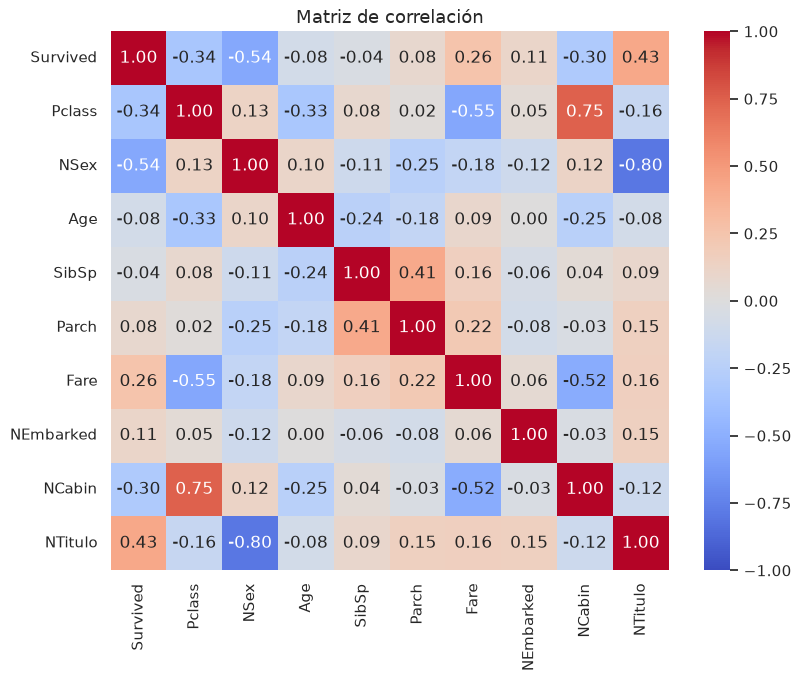

In [44]:
cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']
corr = df[cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()

In [45]:
# Correlación de cada variable con la supervivencia, ordenada
corr['Survived'].sort_values()

NSex        -0.543351
Pclass      -0.338481
NCabin      -0.301116
Age         -0.080453
SibSp       -0.035322
Parch        0.081629
NEmbarked    0.106811
Fare         0.257307
NTitulo      0.428661
Survived     1.000000
Name: Survived, dtype: float64

## Paso 28. Estadísticas por grupos
Calculadas por `group_stats` en `flows/03_aggregation.py` (capa Gold).

In [46]:
tablas = agg.group_stats(df)
tablas['age_by_survival']

,Survived,count,mean,std,min,25%,50%,75%,max
0,0,549.0,30.562012,12.460355,1.00,23.0,30.726645,35.0,74.0
1,1,342.0,28.410122,13.774087,0.42,21.0,27.915709,35.0,80.0


In [47]:
tablas['survival_by_sex']

,Sex,mean,sum,count
0,female,0.742038,233,314
1,male,0.188908,109,577


In [48]:
tablas['survival_by_pclass']

,Pclass,mean,sum,count
0,1,0.629630,136,216
1,2,0.472826,87,184
2,3,0.242363,119,491


In [49]:
tablas['survival_by_alone']

,Alone,mean,sum,count
0,Alone,0.303538,163,537
1,with Family,0.505650,179,354


## Paso 29. ¿La diferencia por sexo es significativa? (chi-cuadrado)
- **H₀:** `Sex` y `Survived` son independientes.
- **H₁:** sí hay asociación.

Si `p < 0.05` se rechaza H₀.

In [50]:
pd.crosstab(df['Sex'], df['Survived'])

Survived,0,1
Sex,,
female,81,233
male,468,109


In [51]:
res = agg.chi2_sex_survival(df)
print(f"chi2 = {res['chi2']:.1f}, p = {res['p_value']:.2e}, gl = {res['dof']}")

chi2 = 260.7, p = 1.20e-58, gl = 1


# 7. Visualizaciones comparativas avanzadas

## Paso 30. Boxplots múltiples (2×2)
Se usa `AgeOriginal` para ver solo edades reales (la imputada concentraría valores en los promedios).

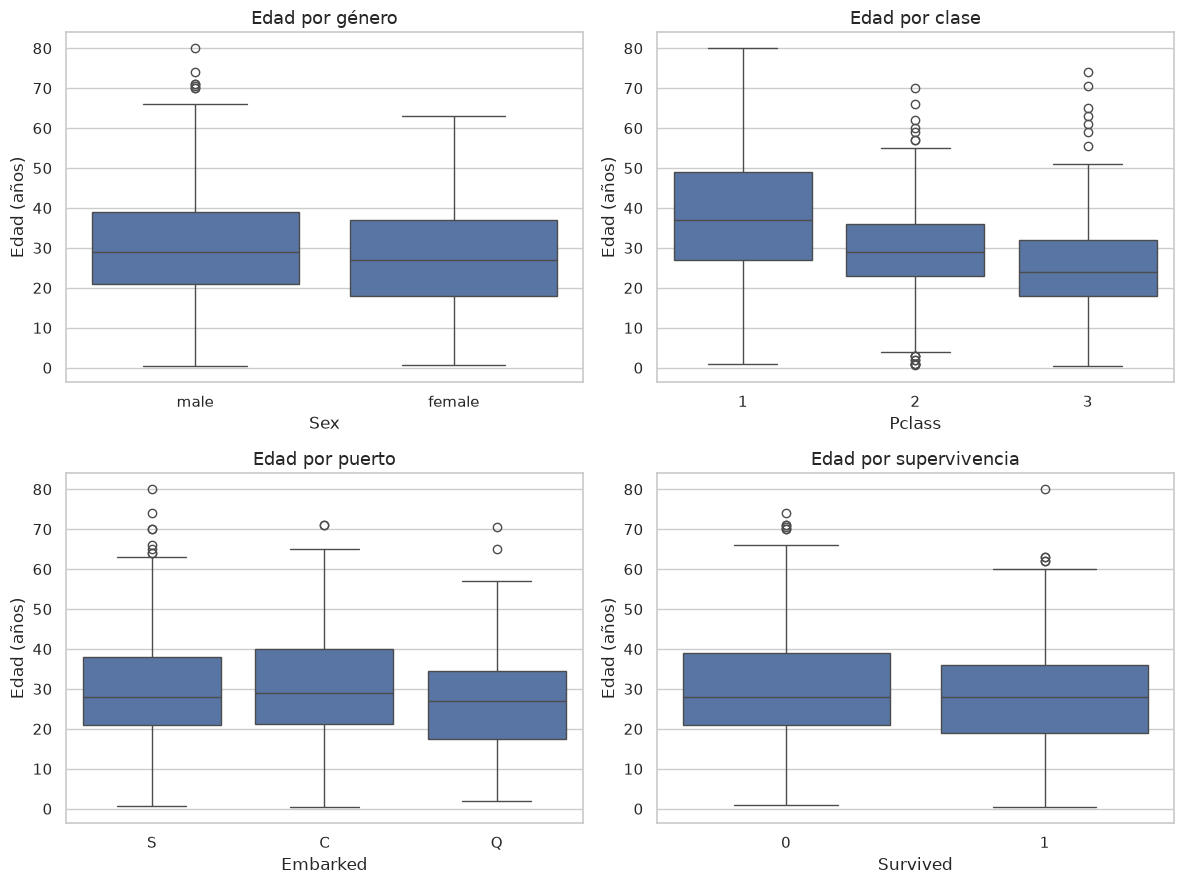

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.boxplot(data=df, x='Sex', y='AgeOriginal', ax=axes[0, 0])
sns.boxplot(data=df, x='Pclass', y='AgeOriginal', ax=axes[0, 1])
sns.boxplot(data=df, x='Embarked', y='AgeOriginal', ax=axes[1, 0])
sns.boxplot(data=df, x='Survived', y='AgeOriginal', ax=axes[1, 1])
axes[0, 0].set_title('Edad por género')
axes[0, 1].set_title('Edad por clase')
axes[1, 0].set_title('Edad por puerto')
axes[1, 1].set_title('Edad por supervivencia')
for ax in axes.flat:
    ax.set_ylabel('Edad (años)')
plt.tight_layout(); plt.show()

## Paso 31. Distribución de la tarifa

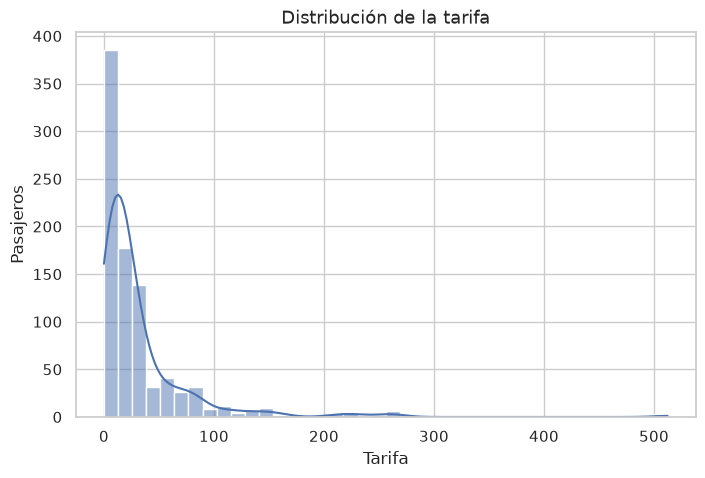

In [53]:
sns.histplot(df['Fare'], kde=True, bins=40)
plt.title('Distribución de la tarifa'); plt.xlabel('Tarifa'); plt.ylabel('Pasajeros')
plt.show()

In [54]:
print(f"Media:     {df['Fare'].mean():.2f}")
print(f"Mediana:   {df['Fare'].median():.2f}")
print(f"Asimetría: {df['Fare'].skew():.2f}")

Media:     32.20
Mediana:   14.45
Asimetría: 4.79


# 8. Dataset final y verificación
`drop_original_columns` genera `titanic_final.parquet` sin `Name`, `Sex`, `Embarked` ni `Cabin`; `validate_silver` hace fallar el pipeline si quedan nulos en columnas clave.

## Paso 32. Vista final (solo columnas derivadas/numéricas)

In [55]:
final = pd.read_parquet(SILVER / SILVER_FINAL_NAME)
print(final.shape)
final.columns.tolist()

(891, 21)


['PassengerId',
 'Survived',
 'Pclass',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Person',
 'TCabin',
 'HasCabin',
 'Familia',
 'Alone',
 'Survivor',
 'TTitulo',
 'AgeOriginal',
 'AgeImputada',
 'NEmbarked',
 'NSex',
 'NCabin',
 'NTitulo']

## Paso 33. Verificación
`AgeOriginal` es la única columna que puede tener nulos (es la edad sin imputar, a propósito).

In [56]:
final.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Person           0
TCabin           0
HasCabin         0
Familia          0
Alone            0
Survivor         0
TTitulo          0
AgeOriginal    177
AgeImputada      0
NEmbarked        0
NSex             0
NCabin           0
NTitulo          0
dtype: int64

In [57]:
final.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Age          891 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Ticket       891 non-null    str    
 7   Fare         891 non-null    float64
 8   Person       891 non-null    str    
 9   TCabin       891 non-null    str    
 10  HasCabin     891 non-null    int64  
 11  Familia      891 non-null    int64  
 12  Alone        891 non-null    str    
 13  Survivor     891 non-null    str    
 14  TTitulo      891 non-null    str    
 15  AgeOriginal  714 non-null    float64
 16  AgeImputada  891 non-null    bool   
 17  NEmbarked    891 non-null    int64  
 18  NSex         891 non-null    int64  
 19  NCabin       891 no

In [58]:
final.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,HasCabin,Familia,AgeOriginal,NEmbarked,NSex,NCabin,NTitulo
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.736034,0.523008,0.381594,32.204208,0.228956,0.904602,29.699118,0.361392,0.647587,6.716049,0.630752
std,257.353842,0.486592,0.836071,13.014897,1.102743,0.806057,49.693429,0.420397,1.613459,14.526497,0.635673,0.477990,2.460739,0.890346
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.420000,0.000000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,0.000000,0.000000,20.125000,0.000000,0.000000,8.000000,0.000000
50%,446.000000,0.000000,3.000000,30.000000,0.000000,0.000000,14.454200,0.000000,0.000000,28.000000,0.000000,1.000000,8.000000,0.000000
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000,0.000000,1.000000,38.000000,1.000000,1.000000,8.000000,1.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,1.000000,10.000000,80.000000,2.000000,1.000000,8.000000,3.000000


# 9. Análisis crítico: interacciones, asociaciones y atípicos
Ya no basta con un número: hay que preguntar si es **grande**, si es **confiable** (¿cuántos pasajeros hay detrás?) y si es **justo** compararlo (¿hay una variable de confusión?).
Cada tabla viene de una función de `flows/03_aggregation.py` (capa Gold).

## Paso 34. Interacción clase × género

In [59]:
agg.survival_by_class_sex(df).round(3)

,Pclass,female,male
0,1,0.968,0.369
1,2,0.921,0.157
2,3,0.500,0.135


## Paso 35. Puerto de embarque y supervivencia (¿confusión?)

In [60]:
agg.survival_by_embarked(df).round(3)

,Embarked,mean,count
0,C,0.554,168
1,Q,0.390,77
2,S,0.339,646


In [61]:
# Estratificado por clase: si dentro de cada clase las diferencias entre puertos se achican,
# el "efecto puerto" era en realidad un efecto de la clase
agg.survival_by_embarked_class(df).round(2)

,Embarked,1,2,3
0,C,0.69,0.53,0.38
1,Q,0.50,0.67,0.38
2,S,0.59,0.46,0.19


## Paso 36. Tarifa y supervivencia dentro de cada clase
`FareQ` = cuartil de la tarifa (0 = más barato, 3 = más caro) calculado **dentro** de cada clase.

In [62]:
agg.survival_by_fare_quartile_class(df).round(2)

,FareQ,1,2,3
0,0,0.46,0.35,0.23
1,1,0.57,0.50,0.20
2,2,0.75,0.58,0.28
3,3,0.74,0.59,0.28


## Paso 37. Tamaño de la familia

In [63]:
agg.survival_by_family(df).round(3)

,Familia,mean,count
0,0,0.304,537
1,1,0.553,161
2,2,0.578,102
3,3,0.724,29
4,4,0.200,15
5,5,0.136,22
6,6,0.333,12
7,7,0.000,6
8,10,0.000,7


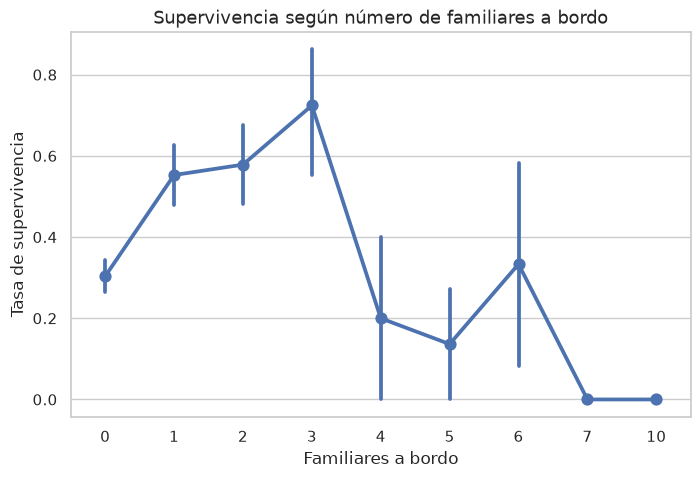

In [64]:
sns.pointplot(data=df, x='Familia', y='Survived')
plt.title('Supervivencia según número de familiares a bordo')
plt.xlabel('Familiares a bordo'); plt.ylabel('Tasa de supervivencia')
plt.show()

## Paso 38. Pasajeros atípicos (regla IQR)
Atípico **no** significa erróneo: antes de eliminar, pregunta si es un error de captura o un caso real.

In [65]:
agg.outlier_summary(df).round(3)

,variable,n_atipicos,tasa_superv_atipicos,tasa_superv_resto
0,Fare,116,0.681,0.339
1,Age,11,0.091,0.388
2,Familia,91,0.341,0.389


In [66]:
# Pasajeros con la tarifa más alta
df.nlargest(10, 'Fare')[['Name', 'Pclass', 'Fare', 'TCabin', 'Survived']]

,Name,Pclass,Fare,TCabin,Survived
258,"Ward, Miss. Anna",1,512.3292,X,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,B,1
737,"Lesurer, Mr. Gustave J",1,512.3292,B,1
27,"Fortune, Mr. Charles Alexander",1,263.0000,C,0
88,"Fortune, Miss. Mabel Helen",1,263.0000,C,1
341,"Fortune, Miss. Alice Elizabeth",1,263.0000,C,1
438,"Fortune, Mr. Mark",1,263.0000,C,0
311,"Ryerson, Miss. Emily Borie",1,262.3750,B,1
742,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.3750,B,1
118,"Baxter, Mr. Quigg Edmond",1,247.5208,B,0
